In [1]:
# ============================================================
# NOTEBOOK 02
# SHAP EXPLAINABILITY + FEATURE ABLATION
# ============================================================
# This notebook continues directly from the checkpoint
# generated by Notebook 01.
#
# Main goals:
# 1. Explain tuned XGBoost predictions using SHAP
# 2. Convert feature-level SHAP into sensor-level evidence
# 3. Perform feature/sensor ablation experiments
# 4. Select the final sensor set for sequence models
# ============================================================

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import joblib
import os

# Evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# XGBoost
from xgboost import XGBRegressor

print("Notebook 02 libraries loaded successfully.")

Notebook 02 libraries loaded successfully.


In [2]:
# ============================================================
# LOAD NOTEBOOK 01 CHECKPOINT
# ============================================================
# Instead of rerunning preprocessing, feature engineering,
# Random Forest, XGBoost, LightGBM and tuning,
# we restore the previously saved state.
# ============================================================

CHECKPOINT_PATH = (
    r"D:\IST\Aircraft_Engine_RUL"
    r"\checkpoints\phase_01_ml_checkpoint.joblib"
)

# Check whether file actually exists
if not os.path.exists(CHECKPOINT_PATH):
    raise FileNotFoundError(
        f"Checkpoint not found:\n{CHECKPOINT_PATH}"
    )

# Load checkpoint
checkpoint = joblib.load(
    CHECKPOINT_PATH
)

print("Checkpoint loaded successfully.")
print("Saved objects:", len(checkpoint))

Checkpoint loaded successfully.
Saved objects: 32


In [3]:
# ============================================================
# RESTORE TRAIN / VALIDATION DATA
# ============================================================

# ----------------------------
# FD002
# ----------------------------

X_train_fd002 = checkpoint[
    "X_train_fd002"
]

X_val_fd002 = checkpoint[
    "X_val_fd002"
]

y_train_fd002 = checkpoint[
    "y_train_fd002"
]

y_val_fd002 = checkpoint[
    "y_val_fd002"
]


# ----------------------------
# FD003
# ----------------------------

X_train_fd003 = checkpoint[
    "X_train_fd003"
]

X_val_fd003 = checkpoint[
    "X_val_fd003"
]

y_train_fd003 = checkpoint[
    "y_train_fd003"
]

y_val_fd003 = checkpoint[
    "y_val_fd003"
]


# ============================================================
# RESTORE TUNED XGBOOST MODELS
# ============================================================

xgb_fd002_tuned = checkpoint[
    "xgb_fd002_tuned"
]

xgb_fd003_tuned = checkpoint[
    "xgb_fd003_tuned"
]


# ============================================================
# RESTORE SENSOR INFORMATION
# ============================================================

candidate_sensor_cols = checkpoint[
    "candidate_sensor_cols"
]

model_sensor_cols = checkpoint[
    "model_sensor_cols"
]

final_sensor_evidence = checkpoint[
    "final_sensor_evidence"
]


print("Required variables restored successfully.")

Required variables restored successfully.


In [4]:
# ============================================================
# CHECKPOINT INTEGRITY CHECK
# ============================================================

print("=" * 60)
print("FD002")
print("=" * 60)

print(
    "X Train:",
    X_train_fd002.shape
)

print(
    "X Validation:",
    X_val_fd002.shape
)

print(
    "y Train:",
    y_train_fd002.shape
)

print(
    "y Validation:",
    y_val_fd002.shape
)


print("\n" + "=" * 60)
print("FD003")
print("=" * 60)

print(
    "X Train:",
    X_train_fd003.shape
)

print(
    "X Validation:",
    X_val_fd003.shape
)

print(
    "y Train:",
    y_train_fd003.shape
)

print(
    "y Validation:",
    y_val_fd003.shape
)


print("\n" + "=" * 60)
print("MODEL CHECK")
print("=" * 60)

print(
    "FD002 Model:",
    type(xgb_fd002_tuned)
)

print(
    "FD003 Model:",
    type(xgb_fd003_tuned)
)

print(
    "\nNumber of candidate sensors:",
    len(candidate_sensor_cols)
)

print(
    "Number of model sensors:",
    len(model_sensor_cols)
)

FD002
X Train: (42424, 166)
X Validation: (10035, 166)
y Train: (42424,)
y Validation: (10035,)

FD003
X Train: (19612, 160)
X Validation: (4608, 160)
y Train: (19612,)
y Validation: (4608,)

MODEL CHECK
FD002 Model: <class 'xgboost.sklearn.XGBRegressor'>
FD003 Model: <class 'xgboost.sklearn.XGBRegressor'>

Number of candidate sensors: 16
Number of model sensors: 16


In [5]:
# ============================================================
# CHECK RESTORED MODEL PREDICTIONS
# ============================================================
# The restored models should immediately predict without
# retraining.
# ============================================================

# FD002 predictions
checkpoint_pred_fd002 = (
    xgb_fd002_tuned.predict(
        X_val_fd002
    )
)

# FD003 predictions
checkpoint_pred_fd003 = (
    xgb_fd003_tuned.predict(
        X_val_fd003
    )
)


# ============================================================
# FD002 METRICS
# ============================================================

checkpoint_mae_fd002 = mean_absolute_error(
    y_val_fd002,
    checkpoint_pred_fd002
)

checkpoint_rmse_fd002 = np.sqrt(
    mean_squared_error(
        y_val_fd002,
        checkpoint_pred_fd002
    )
)

checkpoint_r2_fd002 = r2_score(
    y_val_fd002,
    checkpoint_pred_fd002
)


# ============================================================
# FD003 METRICS
# ============================================================

checkpoint_mae_fd003 = mean_absolute_error(
    y_val_fd003,
    checkpoint_pred_fd003
)

checkpoint_rmse_fd003 = np.sqrt(
    mean_squared_error(
        y_val_fd003,
        checkpoint_pred_fd003
    )
)

checkpoint_r2_fd003 = r2_score(
    y_val_fd003,
    checkpoint_pred_fd003
)


print("========== FD002 RESTORED XGBOOST ==========")

print(
    f"MAE  : {checkpoint_mae_fd002:.4f}"
)

print(
    f"RMSE : {checkpoint_rmse_fd002:.4f}"
)

print(
    f"R²   : {checkpoint_r2_fd002:.4f}"
)


print("\n========== FD003 RESTORED XGBOOST ==========")

print(
    f"MAE  : {checkpoint_mae_fd003:.4f}"
)

print(
    f"RMSE : {checkpoint_rmse_fd003:.4f}"
)

print(
    f"R²   : {checkpoint_r2_fd003:.4f}"
)

========== FD002 RESTORED XGBOOST ==========
MAE  : 12.8267
RMSE : 17.9837
R²   : 0.8151

========== FD003 RESTORED XGBOOST ==========
MAE  : 9.5612
RMSE : 14.3204
R²   : 0.8788


In [6]:
# ============================================================
# IMPORT SHAP
# ============================================================
# SHAP = SHapley Additive exPlanations
#
# It explains how much each feature contributes to
# model predictions.
# ============================================================

import shap

print(
    "SHAP version:",
    shap.__version__
)

SHAP version: 0.52.0


In [7]:
# ============================================================
# CREATE REPRESENTATIVE SHAP SAMPLES
# ============================================================
# Why sample?
#
# SHAP can be computationally expensive.
# We only need a representative validation sample for
# global feature interpretation.
#
# random_state=42 makes the experiment reproducible.
# ============================================================

SHAP_SAMPLE_SIZE = 2000


# ----------------------------
# FD002 sample
# ----------------------------

X_shap_fd002 = X_val_fd002.sample(
    n=min(
        SHAP_SAMPLE_SIZE,
        len(X_val_fd002)
    ),
    random_state=42
)


# ----------------------------
# FD003 sample
# ----------------------------

X_shap_fd003 = X_val_fd003.sample(
    n=min(
        SHAP_SAMPLE_SIZE,
        len(X_val_fd003)
    ),
    random_state=42
)


print(
    "FD002 SHAP Sample:",
    X_shap_fd002.shape
)

print(
    "FD003 SHAP Sample:",
    X_shap_fd003.shape
)

FD002 SHAP Sample: (2000, 166)
FD003 SHAP Sample: (2000, 160)


In [8]:
# ============================================================
# FD002 SHAP EXPLAINER
# ============================================================
# TreeExplainer is specifically optimized for tree models
# such as XGBoost.
# ============================================================

explainer_fd002 = shap.TreeExplainer(
    xgb_fd002_tuned
)

shap_values_fd002 = (
    explainer_fd002.shap_values(
        X_shap_fd002
    )
)

print(
    "FD002 SHAP Values Shape:",
    shap_values_fd002.shape
)

FD002 SHAP Values Shape: (2000, 166)


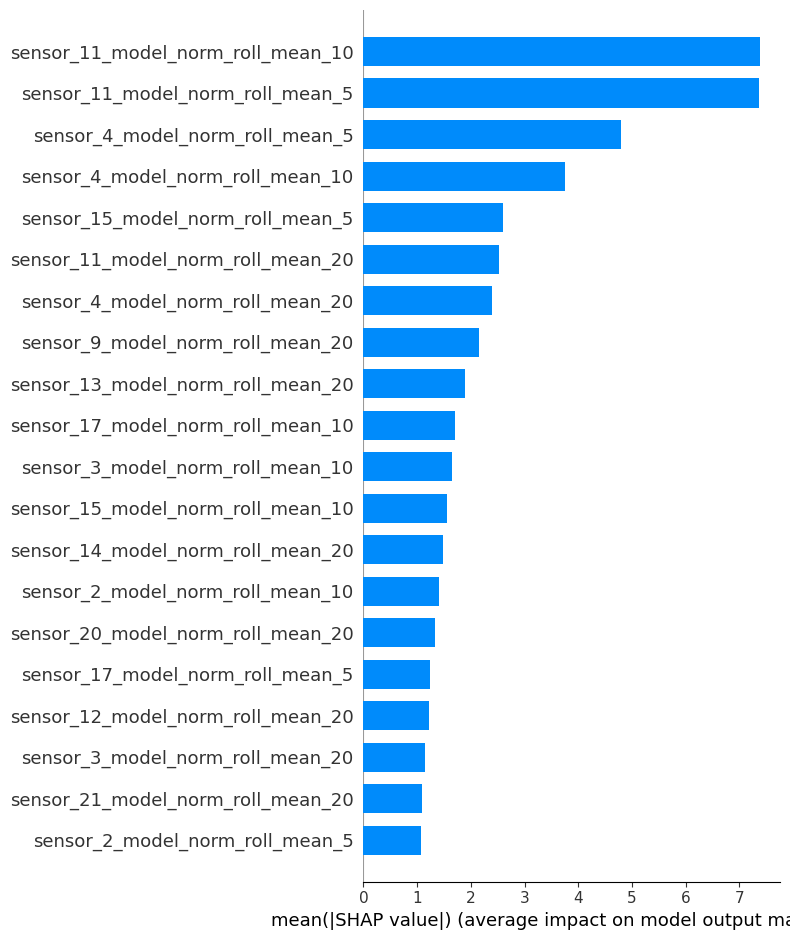

In [9]:
# ============================================================
# FD002 GLOBAL SHAP FEATURE IMPORTANCE
# ============================================================
# Mean absolute SHAP value tells us:
#
# "On average, how strongly does this feature influence
# model predictions?"
#
# Larger bar = greater influence.
# ============================================================

shap.summary_plot(
    shap_values_fd002,
    X_shap_fd002,
    plot_type="bar",
    max_display=20
)

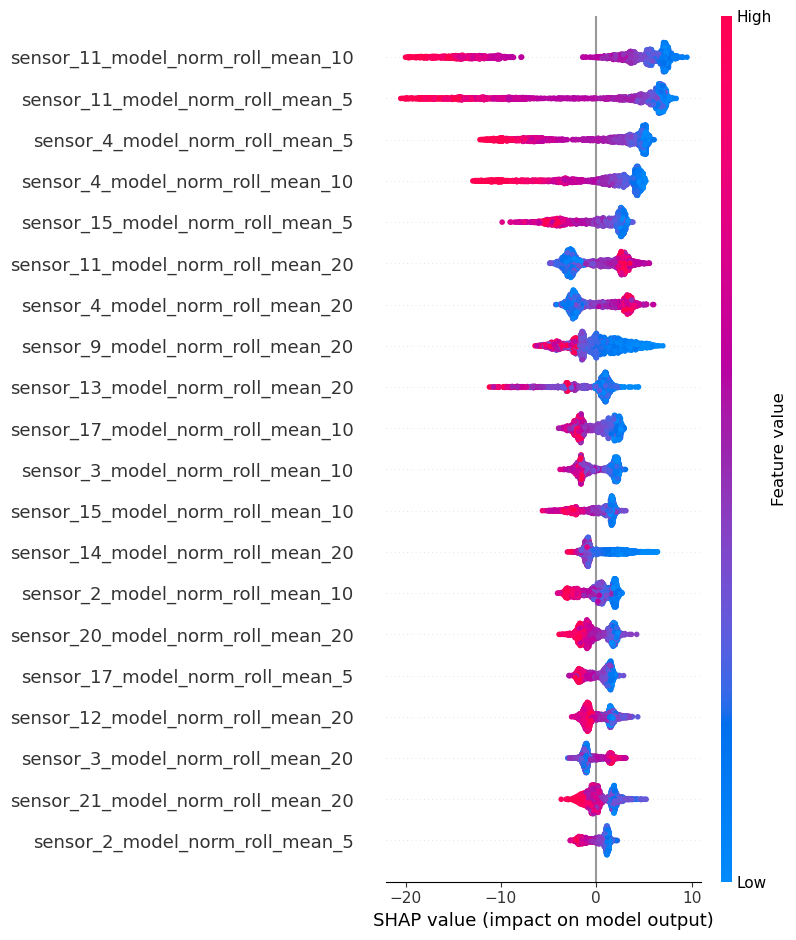

In [10]:
# ============================================================
# FD002 SHAP BEESWARM PLOT
# ============================================================
# This graph shows:
#
# 1. Feature importance
# 2. Feature value magnitude
# 3. Direction of effect on predicted RUL
# ============================================================

shap.summary_plot(
    shap_values_fd002,
    X_shap_fd002,
    max_display=20
)

In [11]:
# ============================================================
# FD002 NUMERICAL SHAP FEATURE IMPORTANCE
# ============================================================
# Absolute SHAP values are averaged across all sampled
# validation observations.
# ============================================================

fd002_shap_importance = pd.DataFrame({

    "Feature":
        X_shap_fd002.columns,

    "Mean_Abs_SHAP":
        np.abs(
            shap_values_fd002
        ).mean(axis=0)
})


# Highest importance first
fd002_shap_importance = (
    fd002_shap_importance
    .sort_values(
        "Mean_Abs_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)


display(
    fd002_shap_importance.head(20)
)

,Feature,Mean_Abs_SHAP
0,sensor_11_model_norm_roll_mean_10,7.390522
1,sensor_11_model_norm_roll_mean_5,7.365288
2,sensor_4_model_norm_roll_mean_5,4.805592
3,sensor_4_model_norm_roll_mean_10,3.749014
4,sensor_15_model_norm_roll_mean_5,2.600905
5,sensor_11_model_norm_roll_mean_20,2.522853
6,sensor_4_model_norm_roll_mean_20,2.392990
7,sensor_9_model_norm_roll_mean_20,2.161106
8,sensor_13_model_norm_roll_mean_20,1.888004
9,sensor_17_model_norm_roll_mean_10,1.701914


In [12]:
# ============================================================
# FD003 SHAP EXPLAINER
# ============================================================

explainer_fd003 = shap.TreeExplainer(
    xgb_fd003_tuned
)

shap_values_fd003 = (
    explainer_fd003.shap_values(
        X_shap_fd003
    )
)

print(
    "FD003 SHAP Values Shape:",
    shap_values_fd003.shape
)

FD003 SHAP Values Shape: (2000, 160)


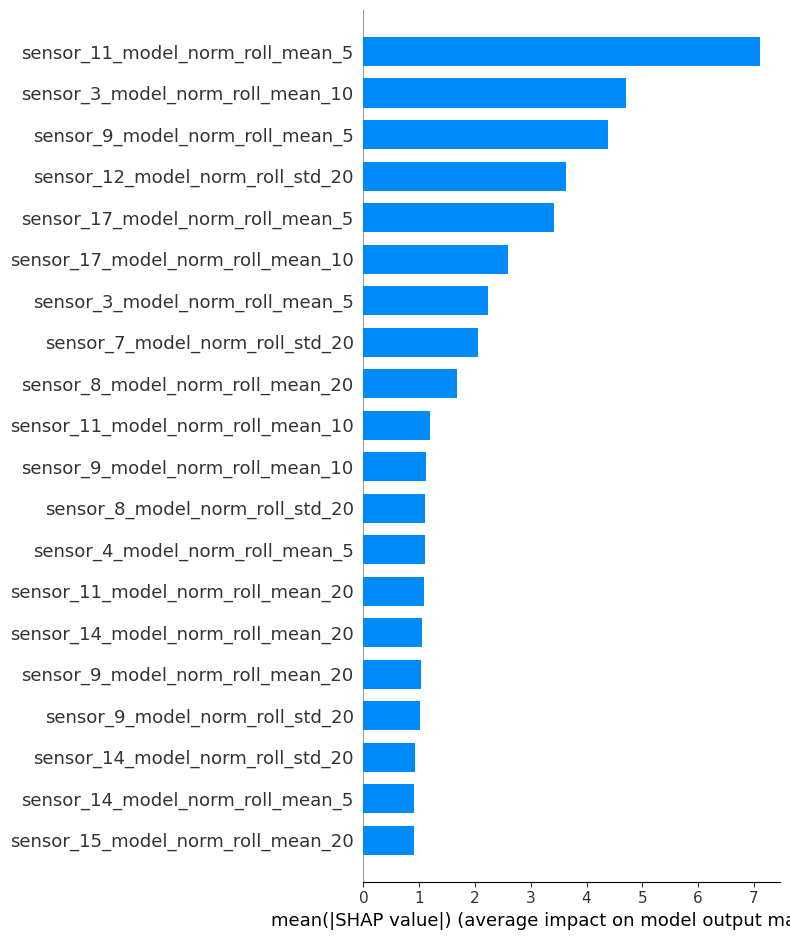

In [13]:
# ============================================================
# FD003 GLOBAL SHAP IMPORTANCE
# ============================================================

shap.summary_plot(
    shap_values_fd003,
    X_shap_fd003,
    plot_type="bar",
    max_display=20
)

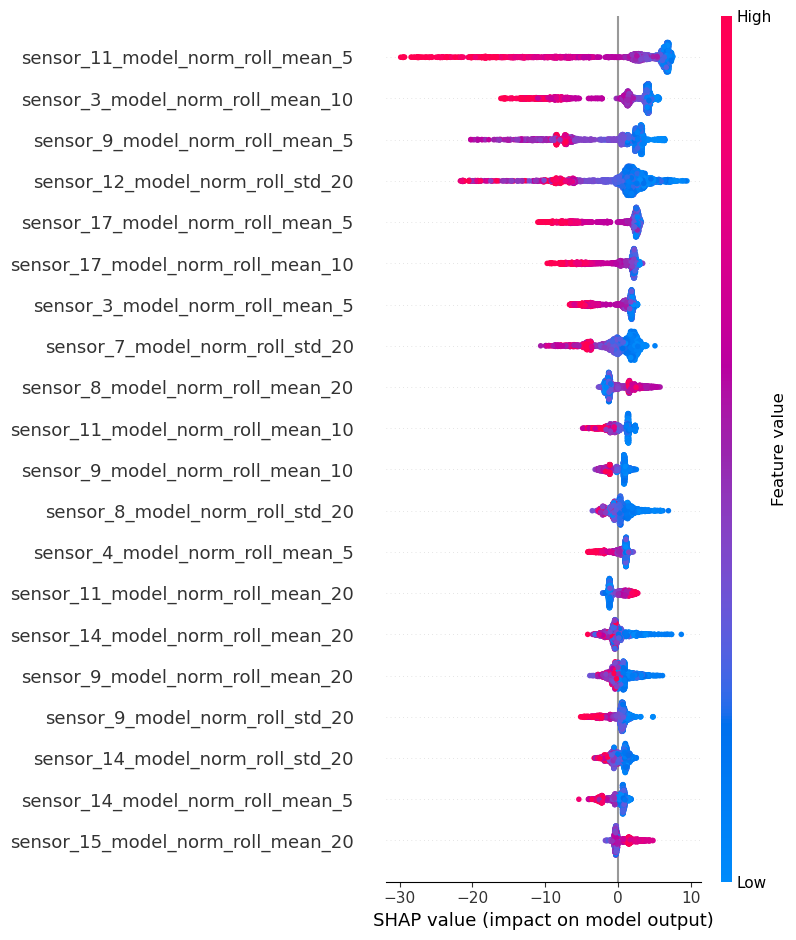

In [14]:
# ============================================================
# FD003 SHAP BEESWARM
# ============================================================

shap.summary_plot(
    shap_values_fd003,
    X_shap_fd003,
    max_display=20
)

In [15]:
# ============================================================
# FD003 NUMERICAL SHAP FEATURE IMPORTANCE
# ============================================================

fd003_shap_importance = pd.DataFrame({

    "Feature":
        X_shap_fd003.columns,

    "Mean_Abs_SHAP":
        np.abs(
            shap_values_fd003
        ).mean(axis=0)
})


fd003_shap_importance = (
    fd003_shap_importance
    .sort_values(
        "Mean_Abs_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)


display(
    fd003_shap_importance.head(20)
)

,Feature,Mean_Abs_SHAP
0,sensor_11_model_norm_roll_mean_5,7.112352
1,sensor_3_model_norm_roll_mean_10,4.707765
2,sensor_9_model_norm_roll_mean_5,4.389042
3,sensor_12_model_norm_roll_std_20,3.632761
4,sensor_17_model_norm_roll_mean_5,3.415667
5,sensor_17_model_norm_roll_mean_10,2.585587
6,sensor_3_model_norm_roll_mean_5,2.236464
7,sensor_7_model_norm_roll_std_20,2.054059
8,sensor_8_model_norm_roll_mean_20,1.677966
9,sensor_11_model_norm_roll_mean_10,1.189829


In [16]:
# ============================================================
# FINAL SENSOR ORDER FROM PREVIOUS EVIDENCE
# ============================================================
# final_sensor_evidence is already sorted from strongest
# to weakest using statistical + traditional ML evidence.
# ============================================================

ranked_sensors = (
    final_sensor_evidence
    .sort_values("Combined_Evidence_Rank")
    .index
    .tolist()
)

print("Final Sensor Ranking:")

for rank, sensor in enumerate(ranked_sensors, start=1):
    print(f"{rank:2d}. {sensor}")

Final Sensor Ranking:
 1. sensor_11
 2. sensor_17
 3. sensor_4
 4. sensor_3
 5. sensor_2
 6. sensor_9
 7. sensor_13
 8. sensor_8
 9. sensor_14
10. sensor_15
11. sensor_12
12. sensor_7
13. sensor_20
14. sensor_21
15. sensor_6
16. sensor_10


In [17]:
# ============================================================
# DEFINE SENSOR SUBSETS FOR ABLATION
# ============================================================
# We systematically reduce the number of sensors while
# preserving their ranking order.
# ============================================================

sensor_sets = {
    "All_16": ranked_sensors[:16],
    "Top_12": ranked_sensors[:12],
    "Top_10": ranked_sensors[:10],
    "Top_8": ranked_sensors[:8]
}


# Display every experimental sensor set
for set_name, sensors in sensor_sets.items():

    print("\n" + "=" * 60)
    print(set_name)
    print("=" * 60)

    print(
        "Number of Sensors:",
        len(sensors)
    )

    print(sensors)


All_16
Number of Sensors: 16
['sensor_11', 'sensor_17', 'sensor_4', 'sensor_3', 'sensor_2', 'sensor_9', 'sensor_13', 'sensor_8', 'sensor_14', 'sensor_15', 'sensor_12', 'sensor_7', 'sensor_20', 'sensor_21', 'sensor_6', 'sensor_10']

Top_12
Number of Sensors: 12
['sensor_11', 'sensor_17', 'sensor_4', 'sensor_3', 'sensor_2', 'sensor_9', 'sensor_13', 'sensor_8', 'sensor_14', 'sensor_15', 'sensor_12', 'sensor_7']

Top_10
Number of Sensors: 10
['sensor_11', 'sensor_17', 'sensor_4', 'sensor_3', 'sensor_2', 'sensor_9', 'sensor_13', 'sensor_8', 'sensor_14', 'sensor_15']

Top_8
Number of Sensors: 8
['sensor_11', 'sensor_17', 'sensor_4', 'sensor_3', 'sensor_2', 'sensor_9', 'sensor_13', 'sensor_8']


In [18]:
# ============================================================
# SELECT ALL ENGINEERED FEATURES BELONGING TO A SENSOR SET
# ============================================================

def get_features_for_sensors(
    dataframe,
    selected_sensors,
    keep_condition_features=False
):
    """
    Select all engineered features generated from the
    requested original sensors.

    Example:
    selected sensor = sensor_11

    Retains:
    sensor_11_model_norm
    sensor_11_model_norm_lag_1
    sensor_11_model_norm_roll_mean_5
    etc.

    FD002 operating-condition one-hot features can optionally
    be retained because they are not sensor features.
    """

    selected_features = []

    # --------------------------------------------------------
    # Select sensor-derived engineered features
    # --------------------------------------------------------

    for feature in dataframe.columns:

        for sensor in selected_sensors:

            # Our engineered feature names begin with:
            # sensor_X_
            if feature.startswith(sensor + "_"):

                selected_features.append(feature)
                break

    # --------------------------------------------------------
    # Preserve FD002 operating-condition features
    # --------------------------------------------------------

    if keep_condition_features:

        condition_features = [
            col
            for col in dataframe.columns
            if col.startswith("condition_")
        ]

        selected_features.extend(
            condition_features
        )

    # Remove any accidental duplicates while preserving order
    selected_features = list(
        dict.fromkeys(selected_features)
    )

    return selected_features

In [19]:
# ============================================================
# CHECK FEATURE COUNT FOR EACH FD002 SENSOR SUBSET
# ============================================================

for set_name, sensors in sensor_sets.items():

    features = get_features_for_sensors(
        X_train_fd002,
        sensors,
        keep_condition_features=True
    )

    print(
        f"{set_name}: "
        f"{len(sensors)} sensors → "
        f"{len(features)} model features"
    )

All_16: 16 sensors → 166 model features
Top_12: 12 sensors → 126 model features
Top_10: 10 sensors → 106 model features
Top_8: 8 sensors → 86 model features


In [20]:
# ============================================================
# CHECK FEATURE COUNT FOR EACH FD003 SENSOR SUBSET
# ============================================================

for set_name, sensors in sensor_sets.items():

    features = get_features_for_sensors(
        X_train_fd003,
        sensors,
        keep_condition_features=False
    )

    print(
        f"{set_name}: "
        f"{len(sensors)} sensors → "
        f"{len(features)} model features"
    )

All_16: 16 sensors → 160 model features
Top_12: 12 sensors → 120 model features
Top_10: 10 sensors → 100 model features
Top_8: 8 sensors → 80 model features


In [21]:
# ============================================================
# ABLATION MODEL EVALUATION FUNCTION
# ============================================================
# Every sensor subset will be evaluated using exactly the
# same metrics and validation protocol.
# ============================================================

import time

from sklearn.base import clone

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


def evaluate_ablation_model(
    base_model,
    X_train,
    y_train,
    X_val,
    y_val,
    selected_features
):
    """
    Retrain the same tuned model using only the selected
    feature subset and evaluate it on the same validation data.
    """

    # Clone keeps the exact tuned hyperparameters but creates
    # a fresh unfitted model for a fair experiment.
    model = clone(base_model)

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    start_train = time.time()

    model.fit(
        X_train[selected_features],
        y_train
    )

    training_time = (
        time.time() - start_train
    )

    # --------------------------------------------------------
    # Validation prediction
    # --------------------------------------------------------

    start_prediction = time.time()

    predictions = model.predict(
        X_val[selected_features]
    )

    inference_time = (
        time.time() - start_prediction
    )

    # --------------------------------------------------------
    # Performance metrics
    # --------------------------------------------------------

    mae = mean_absolute_error(
        y_val,
        predictions
    )

    mse = mean_squared_error(
        y_val,
        predictions
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_val,
        predictions
    )

    return {
        "Model": model,
        "Predictions": predictions,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Training_Time_sec": training_time,
        "Inference_Time_sec": inference_time
    }

In [24]:
# ============================================================
# FD002 SENSOR ABLATION STUDY
# ============================================================
# Base model:
# Tuned XGBoost
#
# Only the number of sensors changes.
# Everything else remains identical.
# ============================================================

fd002_ablation_results = []

# Save trained models separately in case we need the winner
fd002_ablation_models = {}

for set_name, sensors in sensor_sets.items():

    print("\n" + "=" * 65)
    print(f"FD002 Ablation: {set_name}")
    print("=" * 65)

    # Obtain every engineered feature belonging to these sensors
    selected_features = get_features_for_sensors(
        X_train_fd002,
        sensors,
        keep_condition_features=True
    )

    print(
        "Sensors:",
        len(sensors)
    )

    print(
        "Total Model Features:",
        len(selected_features)
    )

    # Train/evaluate same tuned XGBoost architecture
    result = evaluate_ablation_model(
        base_model=xgb_fd002_tuned,
        X_train=X_train_fd002,
        y_train=y_train_fd002,
        X_val=X_val_fd002,
        y_val=y_val_fd002,
        selected_features=selected_features
    )

    # Save trained model
    fd002_ablation_models[
        set_name
    ] = result["Model"]

    # Save experiment results
    fd002_ablation_results.append({
        "Dataset": "FD002",
        "Sensor_Set": set_name,
        "Num_Sensors": len(sensors),
        "Num_Features": len(selected_features),
        "MAE": result["MAE"],
        "RMSE": result["RMSE"],
        "R2": result["R2"],
        "Training_Time_sec":
            result["Training_Time_sec"],
        "Inference_Time_sec":
            result["Inference_Time_sec"]
    })

    print(
        f"MAE  : {result['MAE']:.4f}"
    )

    print(
        f"RMSE : {result['RMSE']:.4f}"
    )

    print(
        f"R²   : {result['R2']:.4f}"
    )

    print(
        f"Training Time: "
        f"{result['Training_Time_sec']:.2f}s"
    )


FD002 Ablation: All_16
Sensors: 16
Total Model Features: 166
MAE  : 12.8267
RMSE : 17.9837
R²   : 0.8151
Training Time: 65.14s

FD002 Ablation: Top_12
Sensors: 12
Total Model Features: 126
MAE  : 12.7229
RMSE : 17.9621
R²   : 0.8155
Training Time: 48.73s

FD002 Ablation: Top_10
Sensors: 10
Total Model Features: 106
MAE  : 12.8189
RMSE : 18.0588
R²   : 0.8135
Training Time: 42.13s

FD002 Ablation: Top_8
Sensors: 8
Total Model Features: 86
MAE  : 13.0563
RMSE : 18.3901
R²   : 0.8066
Training Time: 30.94s


In [25]:
# ============================================================
# FD002 ABLATION RESULTS TABLE
# ============================================================

fd002_ablation_df = pd.DataFrame(
    fd002_ablation_results
)

fd002_ablation_df = (
    fd002_ablation_df
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(fd002_ablation_df)

,Dataset,Sensor_Set,Num_Sensors,Num_Features,MAE,RMSE,R2,Training_Time_sec,Inference_Time_sec
0,FD002,Top_12,12,126,12.722937,17.962124,0.815528,48.732926,0.178785
1,FD002,All_16,16,166,12.826661,17.983665,0.815086,65.144234,0.201029
2,FD002,Top_10,10,106,12.818861,18.058835,0.813536,42.132413,0.155318
3,FD002,Top_8,8,86,13.056256,18.390067,0.806634,30.937117,0.146238


In [26]:
# ============================================================
# FD003 SENSOR ABLATION STUDY
# ============================================================

fd003_ablation_results = []
fd003_ablation_models = {}

for set_name, sensors in sensor_sets.items():

    print("\n" + "=" * 65)
    print(f"FD003 Ablation: {set_name}")
    print("=" * 65)

    # FD003 has only one operating condition,
    # therefore no condition one-hot features are needed.
    selected_features = get_features_for_sensors(
        X_train_fd003,
        sensors,
        keep_condition_features=False
    )

    print(
        "Sensors:",
        len(sensors)
    )

    print(
        "Total Model Features:",
        len(selected_features)
    )

    result = evaluate_ablation_model(
        base_model=xgb_fd003_tuned,
        X_train=X_train_fd003,
        y_train=y_train_fd003,
        X_val=X_val_fd003,
        y_val=y_val_fd003,
        selected_features=selected_features
    )

    fd003_ablation_models[
        set_name
    ] = result["Model"]

    fd003_ablation_results.append({
        "Dataset": "FD003",
        "Sensor_Set": set_name,
        "Num_Sensors": len(sensors),
        "Num_Features": len(selected_features),
        "MAE": result["MAE"],
        "RMSE": result["RMSE"],
        "R2": result["R2"],
        "Training_Time_sec":
            result["Training_Time_sec"],
        "Inference_Time_sec":
            result["Inference_Time_sec"]
    })

    print(
        f"MAE  : {result['MAE']:.4f}"
    )

    print(
        f"RMSE : {result['RMSE']:.4f}"
    )

    print(
        f"R²   : {result['R2']:.4f}"
    )

    print(
        f"Training Time: "
        f"{result['Training_Time_sec']:.2f}s"
    )


FD003 Ablation: All_16
Sensors: 16
Total Model Features: 160
MAE  : 9.5612
RMSE : 14.3204
R²   : 0.8788
Training Time: 26.85s

FD003 Ablation: Top_12
Sensors: 12
Total Model Features: 120
MAE  : 9.5695
RMSE : 14.4310
R²   : 0.8769
Training Time: 19.30s

FD003 Ablation: Top_10
Sensors: 10
Total Model Features: 100
MAE  : 10.1755
RMSE : 15.4281
R²   : 0.8593
Training Time: 15.85s

FD003 Ablation: Top_8
Sensors: 8
Total Model Features: 80
MAE  : 10.3863
RMSE : 15.4209
R²   : 0.8594
Training Time: 11.99s


In [27]:
# ============================================================
# FD003 ABLATION RESULTS TABLE
# ============================================================

fd003_ablation_df = pd.DataFrame(
    fd003_ablation_results
)

fd003_ablation_df = (
    fd003_ablation_df
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(fd003_ablation_df)

,Dataset,Sensor_Set,Num_Sensors,Num_Features,MAE,RMSE,R2,Training_Time_sec,Inference_Time_sec
0,FD003,All_16,16,160,9.561207,14.320447,0.878758,26.849772,0.075938
1,FD003,Top_12,12,120,9.569510,14.431005,0.876878,19.304166,0.077626
2,FD003,Top_8,8,80,10.386343,15.420888,0.859408,11.994905,0.049881
3,FD003,Top_10,10,100,10.175535,15.428058,0.859277,15.847568,0.052600


In [28]:
# ============================================================
# COMBINE FD002 + FD003 ABLATION RESULTS
# ============================================================

ablation_results = pd.concat(
    [
        fd002_ablation_df,
        fd003_ablation_df
    ],
    ignore_index=True
)

display(ablation_results)

,Dataset,Sensor_Set,Num_Sensors,Num_Features,MAE,RMSE,R2,Training_Time_sec,Inference_Time_sec
0,FD002,Top_12,12,126,12.722937,17.962124,0.815528,48.732926,0.178785
1,FD002,All_16,16,166,12.826661,17.983665,0.815086,65.144234,0.201029
2,FD002,Top_10,10,106,12.818861,18.058835,0.813536,42.132413,0.155318
3,FD002,Top_8,8,86,13.056256,18.390067,0.806634,30.937117,0.146238
4,FD003,All_16,16,160,9.561207,14.320447,0.878758,26.849772,0.075938
5,FD003,Top_12,12,120,9.569510,14.431005,0.876878,19.304166,0.077626
6,FD003,Top_8,8,80,10.386343,15.420888,0.859408,11.994905,0.049881
7,FD003,Top_10,10,100,10.175535,15.428058,0.859277,15.847568,0.052600


In [29]:
# ============================================================
# CALCULATE RMSE CHANGE RELATIVE TO ALL 16 SENSORS
# ============================================================

fd002_all16_rmse = (
    fd002_ablation_df
    .loc[
        fd002_ablation_df["Sensor_Set"] == "All_16",
        "RMSE"
    ]
    .iloc[0]
)

fd002_ablation_df["RMSE_Change_vs_All16"] = (
    fd002_ablation_df["RMSE"]
    -
    fd002_all16_rmse
)

display(fd002_ablation_df)

,Dataset,Sensor_Set,Num_Sensors,Num_Features,MAE,RMSE,R2,Training_Time_sec,Inference_Time_sec,RMSE_Change_vs_All16
0,FD002,Top_12,12,126,12.722937,17.962124,0.815528,48.732926,0.178785,-0.021541
1,FD002,All_16,16,166,12.826661,17.983665,0.815086,65.144234,0.201029,0.000000
2,FD002,Top_10,10,106,12.818861,18.058835,0.813536,42.132413,0.155318,0.075170
3,FD002,Top_8,8,86,13.056256,18.390067,0.806634,30.937117,0.146238,0.406403


In [30]:
# ============================================================
# FD003 RMSE CHANGE RELATIVE TO ALL 16
# ============================================================

fd003_all16_rmse = (
    fd003_ablation_df
    .loc[
        fd003_ablation_df["Sensor_Set"] == "All_16",
        "RMSE"
    ]
    .iloc[0]
)

fd003_ablation_df["RMSE_Change_vs_All16"] = (
    fd003_ablation_df["RMSE"]
    -
    fd003_all16_rmse
)

display(fd003_ablation_df)

,Dataset,Sensor_Set,Num_Sensors,Num_Features,MAE,RMSE,R2,Training_Time_sec,Inference_Time_sec,RMSE_Change_vs_All16
0,FD003,All_16,16,160,9.561207,14.320447,0.878758,26.849772,0.075938,0.000000
1,FD003,Top_12,12,120,9.569510,14.431005,0.876878,19.304166,0.077626,0.110558
2,FD003,Top_8,8,80,10.386343,15.420888,0.859408,11.994905,0.049881,1.100440
3,FD003,Top_10,10,100,10.175535,15.428058,0.859277,15.847568,0.052600,1.107611


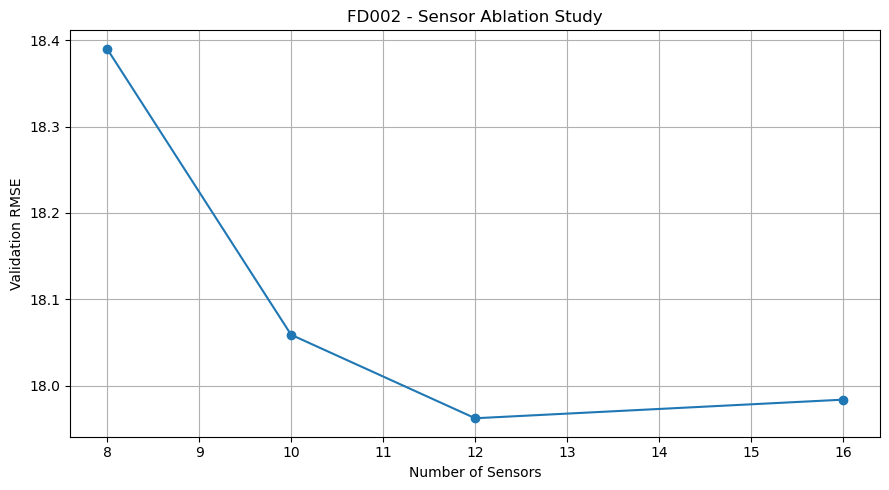

In [31]:
# ============================================================
# FD002 SENSOR ABLATION - RMSE
# ============================================================

plot_fd002 = (
    fd002_ablation_df
    .sort_values("Num_Sensors")
)

plt.figure(figsize=(9, 5))

plt.plot(
    plot_fd002["Num_Sensors"],
    plot_fd002["RMSE"],
    marker="o"
)

plt.xlabel("Number of Sensors")
plt.ylabel("Validation RMSE")

plt.title(
    "FD002 - Sensor Ablation Study"
)

plt.grid()
plt.tight_layout()
plt.show()

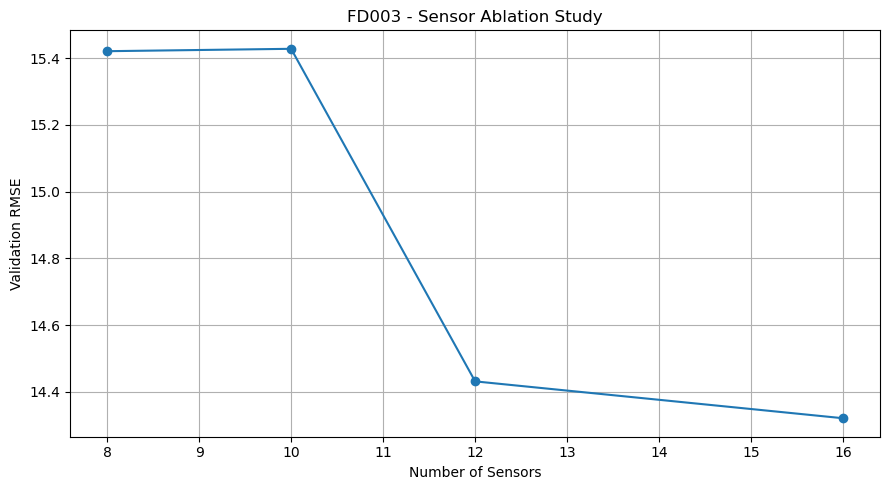

In [32]:
# ============================================================
# FD003 SENSOR ABLATION - RMSE
# ============================================================

plot_fd003 = (
    fd003_ablation_df
    .sort_values("Num_Sensors")
)

plt.figure(figsize=(9, 5))

plt.plot(
    plot_fd003["Num_Sensors"],
    plot_fd003["RMSE"],
    marker="o"
)

plt.xlabel("Number of Sensors")
plt.ylabel("Validation RMSE")

plt.title(
    "FD003 - Sensor Ablation Study"
)

plt.grid()
plt.tight_layout()
plt.show()

In [33]:
# ============================================================
# SENSOR-LEVEL SHAP AGGREGATION
# ============================================================
# Purpose:
# Convert engineered-feature SHAP importance into original
# sensor-level importance.
#
# Example:
# sensor_11_roll_mean_5
# sensor_11_roll_mean_10
# sensor_11_lag_1
#        ↓
# sensor_11
# ============================================================

def aggregate_shap_by_sensor(
    shap_importance_df,
    sensor_list
):
    
    sensor_results = []

    # Process every original sensor
    for sensor in sensor_list:

        # Select all engineered features belonging
        # to the current sensor
        sensor_features = (
            shap_importance_df[
                shap_importance_df["Feature"]
                .str.startswith(sensor + "_")
            ]
        )

        # Sum SHAP importance across the complete
        # engineered feature family
        total_shap = (
            sensor_features["Mean_Abs_SHAP"].sum()
        )

        sensor_results.append({
            "Sensor": sensor,
            "Total_SHAP_Importance": total_shap,
            "Num_Engineered_Features":
                len(sensor_features)
        })

    # Convert results into DataFrame
    result_df = pd.DataFrame(
        sensor_results
    )

    # Strongest sensor first
    result_df = (
        result_df
        .sort_values(
            "Total_SHAP_Importance",
            ascending=False
        )
        .reset_index(drop=True)
    )

    return result_df

In [34]:
# ============================================================
# FD002 SENSOR-LEVEL SHAP
# ============================================================

fd002_sensor_shap = aggregate_shap_by_sensor(
    fd002_shap_importance,
    ranked_sensors
)

display(fd002_sensor_shap)

,Sensor,Total_SHAP_Importance,Num_Engineered_Features
0,sensor_11,18.970343,10
1,sensor_4,12.081418,10
2,sensor_15,6.345076,10
3,sensor_3,4.444119,10
4,sensor_13,4.364556,10
5,sensor_9,4.326034,10
6,sensor_17,4.135681,10
7,sensor_2,3.800105,10
8,sensor_14,3.486551,10
9,sensor_12,3.148407,10


In [35]:
# ============================================================
# FD003 SENSOR-LEVEL SHAP
# ============================================================

fd003_sensor_shap = aggregate_shap_by_sensor(
    fd003_shap_importance,
    ranked_sensors
)

display(fd003_sensor_shap)

,Sensor,Total_SHAP_Importance,Num_Engineered_Features
0,sensor_11,11.027762,10
1,sensor_9,8.546106,10
2,sensor_3,7.731928,10
3,sensor_17,6.719191,10
4,sensor_12,5.267800,10
5,sensor_7,4.084005,10
6,sensor_14,4.022529,10
7,sensor_8,3.805239,10
8,sensor_4,3.129930,10
9,sensor_13,2.928720,10


In [36]:
# ============================================================
# NORMALIZE SENSOR-LEVEL SHAP IMPORTANCE
# ============================================================

fd002_sensor_shap["SHAP_Percentage"] = (
    fd002_sensor_shap["Total_SHAP_Importance"]
    /
    fd002_sensor_shap["Total_SHAP_Importance"].sum()
) * 100


fd003_sensor_shap["SHAP_Percentage"] = (
    fd003_sensor_shap["Total_SHAP_Importance"]
    /
    fd003_sensor_shap["Total_SHAP_Importance"].sum()
) * 100


print("FD002 Sensor-Level SHAP")
display(fd002_sensor_shap)

print("\nFD003 Sensor-Level SHAP")
display(fd003_sensor_shap)

FD002 Sensor-Level SHAP


,Sensor,Total_SHAP_Importance,Num_Engineered_Features,SHAP_Percentage
0,sensor_11,18.970343,10,24.406055
1,sensor_4,12.081418,10,15.543197
2,sensor_15,6.345076,10,8.163177
3,sensor_3,4.444119,10,5.717526
4,sensor_13,4.364556,10,5.615165
5,sensor_9,4.326034,10,5.565605
6,sensor_17,4.135681,10,5.320709
7,sensor_2,3.800105,10,4.888977
8,sensor_14,3.486551,10,4.485579
9,sensor_12,3.148407,10,4.050543



FD003 Sensor-Level SHAP


,Sensor,Total_SHAP_Importance,Num_Engineered_Features,SHAP_Percentage
0,sensor_11,11.027762,10,16.479305
1,sensor_9,8.546106,10,12.770849
2,sensor_3,7.731928,10,11.554185
3,sensor_17,6.719191,10,10.040804
4,sensor_12,5.267800,10,7.871923
5,sensor_7,4.084005,10,6.102922
6,sensor_14,4.022529,10,6.011055
7,sensor_8,3.805239,10,5.686349
8,sensor_4,3.129930,10,4.677202
9,sensor_13,2.928720,10,4.376525


In [37]:
# ============================================================
# COMBINE FD002 AND FD003 SENSOR-LEVEL SHAP
# ============================================================

combined_sensor_shap = pd.merge(

    fd002_sensor_shap[
        ["Sensor", "SHAP_Percentage"]
    ],

    fd003_sensor_shap[
        ["Sensor", "SHAP_Percentage"]
    ],

    on="Sensor",

    suffixes=(
        "_FD002",
        "_FD003"
    )
)


# Average normalized importance across both datasets
combined_sensor_shap[
    "Average_SHAP_Percentage"
] = (

    combined_sensor_shap[
        "SHAP_Percentage_FD002"
    ]

    +

    combined_sensor_shap[
        "SHAP_Percentage_FD003"
    ]

) / 2


# Strongest overall first
combined_sensor_shap = (
    combined_sensor_shap
    .sort_values(
        "Average_SHAP_Percentage",
        ascending=False
    )
    .reset_index(drop=True)
)


display(combined_sensor_shap)

,Sensor,SHAP_Percentage_FD002,SHAP_Percentage_FD003,Average_SHAP_Percentage
0,sensor_11,24.406055,16.479305,20.442680
1,sensor_4,15.543197,4.677202,10.110199
2,sensor_9,5.565605,12.770849,9.168227
3,sensor_3,5.717526,11.554185,8.635856
4,sensor_17,5.320709,10.040804,7.680757
5,sensor_15,8.163177,3.840233,6.001705
6,sensor_12,4.050543,7.871923,5.961233
7,sensor_14,4.485579,6.011055,5.248317
8,sensor_13,5.615165,4.376525,4.995845
9,sensor_7,2.739099,6.102922,4.421010


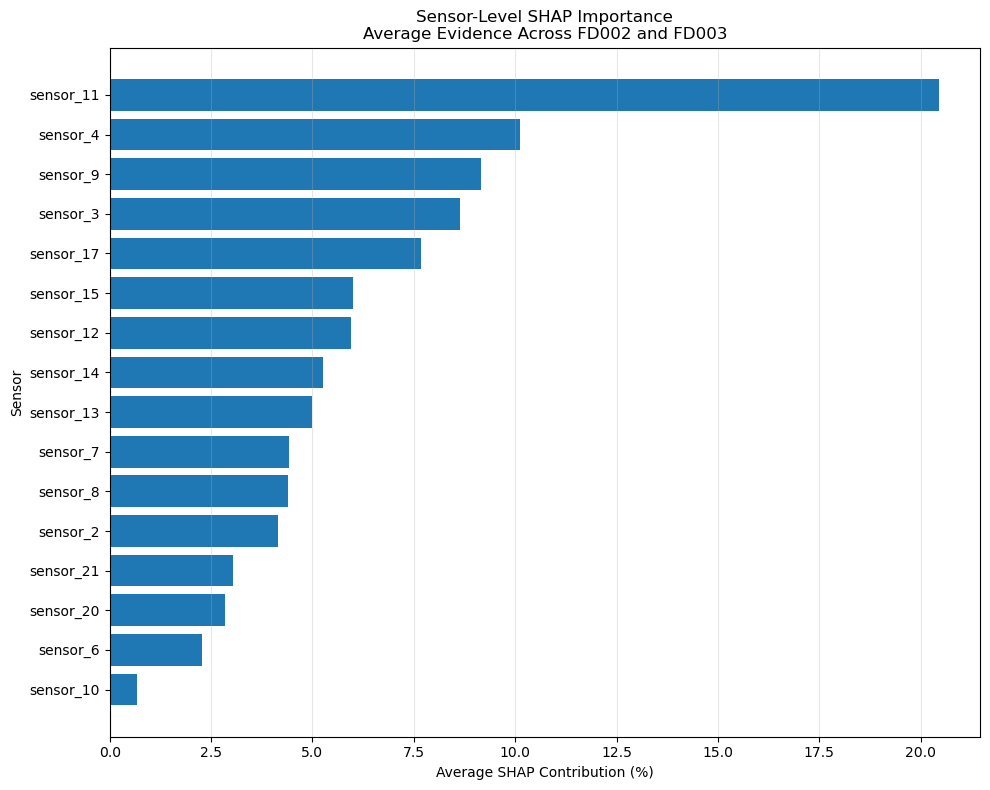

In [38]:
# ============================================================
# COMBINED SENSOR-LEVEL SHAP GRAPH
# ============================================================

plot_data = (
    combined_sensor_shap
    .sort_values(
        "Average_SHAP_Percentage",
        ascending=True
    )
)

plt.figure(
    figsize=(10, 8)
)

plt.barh(
    plot_data["Sensor"],
    plot_data["Average_SHAP_Percentage"]
)

plt.xlabel(
    "Average SHAP Contribution (%)"
)

plt.ylabel(
    "Sensor"
)

plt.title(
    "Sensor-Level SHAP Importance\n"
    "Average Evidence Across FD002 and FD003"
)

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [40]:
# ============================================================
# CHECK AVAILABLE FD002 / FD003 DATA VARIABLES
# ============================================================
# Purpose:
# Find exactly which processed datasets currently exist
# in notebook memory before saving the Deep Learning checkpoint.
# ============================================================

print("=" * 60)
print("AVAILABLE FD002 VARIABLES")
print("=" * 60)

for name in sorted(globals()):
    if "fd002" in name.lower():
        obj = globals()[name]

        # Print variable name and shape if available
        shape = getattr(obj, "shape", None)

        print(
            f"{name:<40} Shape: {shape}"
        )


print("\n" + "=" * 60)
print("AVAILABLE FD003 VARIABLES")
print("=" * 60)

for name in sorted(globals()):
    if "fd003" in name.lower():
        obj = globals()[name]

        # Print variable name and shape if available
        shape = getattr(obj, "shape", None)

        print(
            f"{name:<40} Shape: {shape}"
        )

AVAILABLE FD002 VARIABLES
X_shap_fd002                             Shape: (2000, 166)
X_train_fd002                            Shape: (42424, 166)
X_val_fd002                              Shape: (10035, 166)
checkpoint_mae_fd002                     Shape: None
checkpoint_pred_fd002                    Shape: (10035,)
checkpoint_r2_fd002                      Shape: None
checkpoint_rmse_fd002                    Shape: ()
explainer_fd002                          Shape: None
fd002_ablation_df                        Shape: (4, 10)
fd002_ablation_models                    Shape: None
fd002_ablation_results                   Shape: None
fd002_all16_rmse                         Shape: ()
fd002_sensor_shap                        Shape: (16, 4)
fd002_shap_importance                    Shape: (166, 2)
plot_fd002                               Shape: (4, 10)
shap_values_fd002                        Shape: (2000, 166)
xgb_fd002_tuned                          Shape: None
y_train_fd002                 

In [41]:
# ============================================================
# RESTORE ENGINE-WISE PROCESSED DATA FOR DEEP LEARNING
# ============================================================
# Purpose:
# BiLSTM and CAUC-AeroRULNet require chronological
# engine sequences.
#
# Therefore we restore the leakage-free processed DataFrames
# from Notebook 01 instead of using the tabular X matrices.
# ============================================================

# ----------------------------
# FD002
# ----------------------------

fd002_train_model = checkpoint[
    "fd002_train_model"
].copy()

fd002_val_model = checkpoint[
    "fd002_val_model"
].copy()


# ----------------------------
# FD003
# ----------------------------

fd003_train_model = checkpoint[
    "fd003_train_model"
].copy()

fd003_val_model = checkpoint[
    "fd003_val_model"
].copy()


print("Engine-wise processed datasets restored successfully.")

print("\nFD002:")
print("Train:", fd002_train_model.shape)
print("Val  :", fd002_val_model.shape)

print("\nFD003:")
print("Train:", fd003_train_model.shape)
print("Val  :", fd003_val_model.shape)

Engine-wise processed datasets restored successfully.

FD002:
Train: (43464, 66)
Val  : (10295, 66)

FD003:
Train: (20012, 65)
Val  : (4708, 65)


In [42]:
# ============================================================
# VERIFY DEEP LEARNING DATA STRUCTURE
# ============================================================
# We need:
# engine_id      -> keeps engines separate
# cycle          -> chronological order
# RUL_capped     -> regression target
# model sensors  -> normalized leakage-free sensor inputs
# ============================================================

required_dl_columns = (
    ["engine_id", "cycle", "RUL_capped"]
    + model_sensor_cols
)


def check_dl_columns(df, dataset_name):
    """
    Check whether every column required for sequence
    generation exists in the processed DataFrame.
    """

    missing_columns = [
        col
        for col in required_dl_columns
        if col not in df.columns
    ]

    print(f"\n{dataset_name}")

    if len(missing_columns) == 0:
        print("✅ All Deep Learning columns available.")

    else:
        print("❌ Missing columns:")
        print(missing_columns)


check_dl_columns(
    fd002_train_model,
    "FD002 Train"
)

check_dl_columns(
    fd002_val_model,
    "FD002 Validation"
)

check_dl_columns(
    fd003_train_model,
    "FD003 Train"
)

check_dl_columns(
    fd003_val_model,
    "FD003 Validation"
)


FD002 Train
✅ All Deep Learning columns available.

FD002 Validation
✅ All Deep Learning columns available.

FD003 Train
✅ All Deep Learning columns available.

FD003 Validation
✅ All Deep Learning columns available.


In [43]:
# ============================================================
# INSPECT DEEP LEARNING DATA
# ============================================================

display(
    fd002_train_model[
        [
            "engine_id",
            "cycle",
            "RUL_capped"
        ]
        + model_sensor_cols[:5]
    ].head(10)
)

,engine_id,cycle,RUL_capped,sensor_2_model_norm,sensor_3_model_norm,sensor_4_model_norm,sensor_6_model_norm,sensor_7_model_norm
0,1,1,125,-1.098261,-1.459776,0.765024,-0.165274,0.424383
1,1,2,125,0.445888,-0.229692,-0.275109,-1.188276,-0.264832
2,1,3,125,1.244750,-1.127931,-0.429323,-1.870974,0.637831
3,1,4,125,-0.459146,-0.085012,-0.196605,-1.188276,-0.378242
4,1,5,125,0.572492,-0.948582,-0.358696,0.530575,-0.835596
5,1,6,125,0.432438,0.688216,-0.242457,0.530575,-0.567700
6,1,7,125,0.074592,-1.260313,-0.090626,-1.188276,0.188807
7,1,8,125,-0.278324,-0.677141,-0.106826,-1.400741,-0.137256
8,1,9,125,-0.876855,-1.120992,-0.056607,-1.188276,-1.285520
9,1,10,125,-0.876855,0.338311,-0.101093,-1.188276,0.166125


In [44]:
# ============================================================
# SAVE NOTEBOOK 02 → DEEP LEARNING CHECKPOINT
# ============================================================
# Purpose:
# Save only the objects needed for the upcoming
# sequence-modeling phase.
#
# Notebook 03 will therefore NOT need:
# - EDA rerun
# - RF training
# - XGBoost training
# - LightGBM training
# - SHAP rerun
# ============================================================

import os
import joblib


# ------------------------------------------------------------
# Checkpoint directory
# ------------------------------------------------------------

checkpoint_dir = (
    r"D:\IST\Aircraft_Engine_RUL\checkpoints"
)

os.makedirs(
    checkpoint_dir,
    exist_ok=True
)


# ------------------------------------------------------------
# Build Deep Learning checkpoint
# ------------------------------------------------------------

deep_learning_checkpoint = {

    # ========================================================
    # ENGINE-WISE LEAKAGE-FREE DATA
    # ========================================================

    "fd002_train_model":
        fd002_train_model,

    "fd002_val_model":
        fd002_val_model,

    "fd003_train_model":
        fd003_train_model,

    "fd003_val_model":
        fd003_val_model,


    # ========================================================
    # SENSOR INFORMATION
    # ========================================================

    "candidate_sensor_cols":
        candidate_sensor_cols,

    "model_sensor_cols":
        model_sensor_cols,

    "ranked_sensors":
        ranked_sensors,

    # FD002 ablation winner
    "top_12_sensors":
        ranked_sensors[:12],


    # ========================================================
    # FEATURE-SELECTION / EXPLAINABILITY EVIDENCE
    # ========================================================

    "final_sensor_evidence":
        final_sensor_evidence,

    "fd002_sensor_shap":
        fd002_sensor_shap,

    "fd003_sensor_shap":
        fd003_sensor_shap,

    "combined_sensor_shap":
        combined_sensor_shap,

    "fd002_ablation_df":
        fd002_ablation_df,

    "fd003_ablation_df":
        fd003_ablation_df,


    # ========================================================
    # PREPROCESSING OBJECTS
    # Needed later for deployment / unseen data
    # ========================================================

    "fd002_op_scaler_model":
        checkpoint["fd002_op_scaler_model"],

    "fd002_kmeans_model":
        checkpoint["fd002_kmeans_model"],

    "fd002_model_condition_means":
        checkpoint["fd002_model_condition_means"],

    "fd002_model_safe_stds":
        checkpoint["fd002_model_safe_stds"],

    "fd003_model_means":
        checkpoint["fd003_model_means"],

    "fd003_model_safe_stds":
        checkpoint["fd003_model_safe_stds"]
}


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

DL_CHECKPOINT_PATH = os.path.join(
    checkpoint_dir,
    "phase_02_deep_learning_checkpoint.joblib"
)


joblib.dump(
    deep_learning_checkpoint,
    DL_CHECKPOINT_PATH,
    compress=3
)


print("✅ Deep Learning checkpoint saved successfully.")
print(DL_CHECKPOINT_PATH)

✅ Deep Learning checkpoint saved successfully.
D:\IST\Aircraft_Engine_RUL\checkpoints\phase_02_deep_learning_checkpoint.joblib


In [45]:
# ============================================================
# VERIFY DEEP LEARNING CHECKPOINT
# ============================================================

print(
    "Checkpoint exists:",
    os.path.exists(DL_CHECKPOINT_PATH)
)

checkpoint_size_mb = (
    os.path.getsize(DL_CHECKPOINT_PATH)
    / (1024 ** 2)
)

print(
    f"Checkpoint Size: {checkpoint_size_mb:.2f} MB"
)


# Test-load
test_dl_checkpoint = joblib.load(
    DL_CHECKPOINT_PATH
)

print(
    "Checkpoint loads correctly:",
    isinstance(test_dl_checkpoint, dict)
)

print(
    "Saved objects:",
    len(test_dl_checkpoint)
)

Checkpoint exists: True
Checkpoint Size: 11.95 MB
Checkpoint loads correctly: True
Saved objects: 20
